# 9. Gravitational-wave perturbations
Write $g=\eta+h$. Under $x\to x+\xi$, $h_{\mu\nu}\to h_{\mu\nu}+\partial_\mu\xi_\nu+\partial_\nu\xi_\mu$. The linearised Riemann tensor is invariant, so most of the ten components of $h$ are gauge. In TT gauge a vacuum wave has two polarisations $h_+,h_\times$, and satisfies the field equations only if $k=\omega$.

In [1]:
import sympy as sp
from gr_from_scratch.field_equations import linearized_gravity as lg
t, x, y, z = sp.symbols('t x y z', real=True); X = [t, x, y, z]
h = sp.Matrix(4, 4, lambda a, b: sp.Function(f'h{min(a,b)}{max(a,b)}')(*X))
xi = [sp.Function(f'xi{i}')(*X) for i in range(4)]
R1 = lg.linearized_riemann(h, X); R2 = lg.linearized_riemann(lg.gauge_transform(h, xi, X), X)
print('linearised Riemann gauge invariant:', all(sp.simplify(a-b)==0 for a,b in zip(R1.ravel(), R2.ravel())))

w, k, A, B = sp.symbols('omega k A B', positive=True)
hw = lg.plane_wave_tt(X, A, B, w, k=k)
print('TT conditions:', lg.tt_conditions(hw, X))
G = lg.linearized_einstein(hw, X)
print('vacuum if k=omega:', all(sp.simplify(e.subs(k, w))==0 for e in G), '| with k != omega, nonzero:', any(sp.simplify(e)!=0 for e in G))

linearised Riemann gauge invariant: True
TT conditions: (0, [0, 0, 0, 0], [0, 0, 0, 0])


vacuum if k=omega: True | with k != omega, nonzero: True


**Test particles.** The linearised geodesic-deviation equation $\ddot\xi^i=\tfrac12\ddot h_{ij}\xi^j$ is compared with the exact proper separation of particles held at fixed TT coordinates. They should differ at $O(A^2)$.

slope of difference vs amplitude: 2.0027826465630016


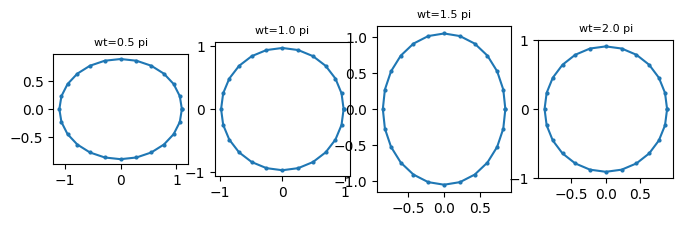

In [2]:
import numpy as np, matplotlib.pyplot as plt
from gr_from_scratch.dynamics.gravitational_waves import integrate_deviation, proper_separation
amps = np.array([1e-3, 3e-3, 1e-2, 3e-2, 1e-1]); diffs = []
for A in amps:
    ts, xi_ = integrate_deviation((1,0), A, 0.0, 1.0, 4*np.pi, n=801)
    diffs.append(np.abs(np.linalg.norm(xi_, axis=1) - proper_separation(ts, (1,0), A, 0.0, 1.0)).max())
print('slope of difference vs amplitude:', np.polyfit(np.log(amps), np.log(diffs), 1)[0])

th = np.linspace(0, 2*np.pi, 25)[:-1]
fig, axs = plt.subplots(1, 4, figsize=(8, 2.2))
for ax, ph in zip(axs, [np.pi/2, np.pi, 3*np.pi/2, 2*np.pi]):
    pts = np.array([integrate_deviation((np.cos(a), np.sin(a)), 0.2, 0.0, 1.0, ph, n=3)[1][-1] for a in th])
    ax.plot(*np.vstack([pts, pts[:1]]).T, '-o', ms=2); ax.set_aspect('equal'); ax.set_title(f'wt={ph/np.pi:.1f} pi', fontsize=8)
plt.show()